## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

In [2]:
# ============================================================
# Task 1: Các thành phần của bài toán tìm kiếm cho Connect 4
# ============================================================
# 1. Trạng thái đầu (initial state)
#    Bàn cờ rỗng kích thước (6, 7): mỗi ô bằng 0.
#    Quy ước: 0 = trống, 1 = đỏ (red), -1 = vàng (yellow).
#    Đỏ đi trước.
#
# 2. Hành động (actions)
#    Một nước đi chỉ là chỉ số cột c (0..6) mà ô trên cùng còn trống.
#    Không cần chọn hàng: quân luôn rơi xuống ô trống thấp nhất của cột,
#    nên chỉ cần cột là đủ để xác định nước đi.
#    Số hành động tối đa mỗi trạng thái = số cột = 7.
#
# 3. Mô hình chuyển trạng thái (result)
#    Copy bàn cờ, đặt quân của player vào ô trống thấp nhất của cột được
#    chọn, trả về bàn cờ mới. Bàn cờ cũ không bị sửa (immutable).
#    Cột đã đầy => nước đi không hợp lệ, ném ValueError.
#
# 4. Trạng thái kết thúc (terminal)
#    Kết thúc khi: một bên có 4 quân liên tiếp theo hàng, cột hoặc đường
#    chéo, HOẶC bàn cờ đã đầy (kết quả hòa).
#
# 5. Hàm lợi ích (utility)
#    utility = +1 nếu player thắng, -1 nếu player thua, 0 nếu hòa.
#    Trạng thái chưa kết thúc trả về None (giống ví dụ tic-tac-toe).
#
# Nhận xét về biểu diễn: bàn cờ chỉ lưu 1/-1/0 nên hai thứ tự nước đi
# khác nhau cho ra cùng một thế cờ được coi là MỘT trạng thái.
# Các hàm được cài đặt ở cell tiếp theo: actions, result, terminal, utility.


How big is the state space? Give an estimate and explain it.

### Kích thước không gian trạng thái

**Cận trên lỏng:** bàn cờ có $6 \times 7 = 42$ ô, mỗi ô nhận 1 trong 3 giá trị
(trống / đỏ / vàng):

$$3^{42} \approx 1.09 \times 10^{20}$$

**Cận trên chặt hơn:** bàn cờ thật không phải lưới tô màu tuỳ ý —

* mỗi cột đầy từ dưới lên (không có quân "lơ lửng"), nên số quân trong một cột
  xác định duy nhất thứ tự màu trong cột đó;
* số quân hai bên chỉ chênh lệch 0 hoặc 1 (đỏ đi trước): $r = y$ hoặc $r = y+1$,
  với $r, y \le 21$.

Với $r + y$ quân đã đặt, số cách chọn vị trí là $\binom{42}{r}\binom{42-r}{y}$,
nên tổng số thế cờ (kể cả thế cờ đã có người thắng) là:

$$\sum_{r,y} \binom{42}{r}\binom{42-r}{y}
\approx 1.63 \times 10^{19}$$

**Số thế cờ hợp lệ thực tế** (đã loại các thế cờ đã kết thúc và các thế cờ
không thể tới được bằng nước đi hợp lệ) đã được công bố là khoảng
$4.53 \times 10^{12}$.

Tóm lại: cận trên $10^{19}$–$10^{20}$, còn số trạng thái thực sự duyệt được
vào cỡ $10^{12}$ — vẫn quá lớn để duyệt vét cạn trên bàn $6 \times 7$.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

### Kích thước cây trò chơi

Cây trò chơi liệt kê **mọi dãy nước đi**, kể cả các dãy dẫn tới cùng một thế cờ.

* Hệ số phân nhánh $b \le 7$ (số cột), giảm dần khi cột đầy.
* Độ sâu tối đa $d = 42$ (bàn cờ đầy).

Cận trên đơn giản khi bỏ qua việc cột đầy dần:

$$\sum_{k=0}^{42} 7^{k} \approx 3.6 \times 10^{35}$$

Chặt hơn một chút: các nút ở độ sâu $k$ chỉ có thể dùng những cột còn trống,
nhưng bậc giảm rất chậm (7, 6, 5, …) nên bậc vẫn xấp xỉ $7^{42} \approx 3.1
\times 10^{35}$.

**Alpha-beta cắt tỉa lý tưởng** chỉ cần duyệt $b^{\lceil d/2 \rceil} +
b^{\lfloor d/2 \rfloor} - 1$, với $b = 7, d = 42$ cho
$2 \cdot 7^{21} \approx 1.1 \times 10^{18}$ nút — vẫn không thể duyệt hết.

Đó là lý do phải dùng **cắt tỉa theo độ sâu + hàm đánh giá heuristic**.


## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    # Bàn cờ rỗng: 0 = trống, 1 = đỏ, -1 = vàng.
    # dtype=int8 đủ để lưu 3 giá trị, tiết kiệm bộ nhớ khi copy bàn cờ.
    return np.zeros(shape=shape, dtype=np.int8)

print(empty_board())


[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

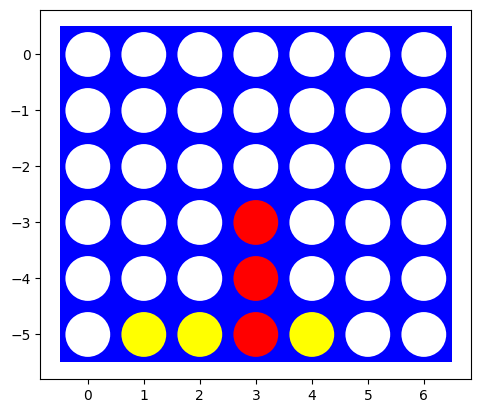

In [4]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [5]:
def actions(board):
    # Các cột còn chỗ quân: cột chưa đầy (ô trên cùng còn trống).
    return [c for c in range(board.shape[1]) if board[0, c] == 0]


def drop(board, col, player):
    # Trả về (bàn_cờ_mới, hàng) hoặc (None, None) nếu cột đã đầy.
    free = np.flatnonzero(board[:, col] == 0)
    if free.size == 0:
        return None, None
    row = int(free[-1])
    new = board.copy()
    new[row, col] = player
    return new, row


def result(board, player, action):
    # Mô hình chuyển trạng thái: đặt quân của player vào cột action.
    new, _ = drop(board, action, player)
    if new is None:
        raise ValueError(f"Illegal action {action} by player {player}")
    return new


def wins_at(board, row, col):
    # Quân vừa đặt tại (row, col) có tạo thành đường 4 quân liên tiếp không?
    p = board[row, col]
    if p == 0:
        return False
    h, w = board.shape
    for dr, dc in ((0, 1), (1, 0), (1, 1), (1, -1)):
        n = 1
        for sign in (1, -1):
            r, c = row + dr * sign, col + dc * sign
            while 0 <= r < h and 0 <= c < w and board[r, c] == p:
                n += 1
                r += dr * sign
                c += dc * sign
        if n >= 4:
            return True
    return False


def wins_any(board, player):
    # Quét toàn bàn cờ xem player đã có 4 quân liên tiếp ở đâu chưa.
    h, w = board.shape
    m = board == player
    if w >= 4:
        for r in range(h):
            for c in range(w - 3):
                if m[r, c] and m[r, c + 1] and m[r, c + 2] and m[r, c + 3]:
                    return True
    if h >= 4:
        for r in range(h - 3):
            for c in range(w):
                if m[r, c] and m[r + 1, c] and m[r + 2, c] and m[r + 3, c]:
                    return True
    if h >= 4 and w >= 4:
        for r in range(h - 3):
            for c in range(w - 3):
                if (m[r, c] and m[r + 1, c + 1] and m[r + 2, c + 2]
                        and m[r + 3, c + 3]):
                    return True
                if (m[r, c + 3] and m[r + 1, c + 2] and m[r + 2, c + 1]
                        and m[r + 3, c]):
                    return True
    return False


def full(board):
    # Bàn cờ đầy khi hàng trên cùng không còn ô trống.
    return not (board[0] == 0).any()


def terminal(board):
    # Kết thúc khi một bên thắng hoặc bàn cờ đầy.
    return wins_any(board, 1) or wins_any(board, -1) or full(board)


def utility(board, player=1):
    # +1 player thắng, -1 player thua, 0 hòa, None nếu chưa kết thúc.
    if wins_any(board, player):
        return 1
    if wins_any(board, -player):
        return -1
    if full(board):
        return 0
    return None


# --- Kiểm tra nhanh (assert) ---
_b = empty_board((4, 4))
for _c in range(4):
    _b = result(_b, 1, _c)
assert wins_any(_b, 1) and terminal(_b)
assert utility(_b, 1) == 1 and utility(_b, -1) == -1
assert actions(empty_board((6, 7))) == list(range(7))
assert drop(result(empty_board((6, 7)), 1, 0), 0, -1)[1] == 4
print("self-check: các hàm hỗ trợ OK")


self-check: các hàm hỗ trợ OK


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
import random


def random_player(board, player=1):
    # Agent ngẫu nhiên: chọn đều một cột còn trống.
    # Không lưu trạng thái nên chỉ cần board và player.
    return random.choice(actions(board))


print("random_player chọn:", random_player(empty_board((6, 7)), 1))


random_player chọn: 2


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
def play(player1, player2, shape=(6, 7), verbose=False):
    # Môi trường trò chơi: player1 là đỏ (1) và đi trước.
    # Trả về (người thắng, danh sách bàn cờ) - 0 nghĩa là hòa.
    board = empty_board(shape)
    history = [board]
    agent, player = player1, 1
    while True:
        col = agent(board, player)
        board, row = drop(board, col, player)
        if board is None:
            raise ValueError(f"Agent returned illegal column {col}")
        history.append(board)
        if verbose:
            print(board, "player", player, "->", col)
        if wins_at(board, row, col):
            return player, history
        if full(board):
            return 0, history
        agent, player = (player2, -1) if player == 1 else (player1, 1)


def play_matches(player1, player2, n=100, shape=(6, 7)):
    # Chơi n ván, đếm số ván thắng cho mỗi bên.
    results = {1: 0, -1: 0, 0: 0}
    for _ in range(n):
        winner, _ = play(player1, player2, shape)
        results[winner] += 1
    return results


random.seed(0)
res = play_matches(random_player, random_player, 1000, (6, 7))
print("1000 ván 6x7  - đỏ thắng:", res[1], "| vàng thắng:", res[-1], "| hòa:", res[0])

random.seed(0)
res_small = play_matches(random_player, random_player, 1000, (4, 4))
print("1000 ván 4x4  - đỏ thắng:", res_small[1], "| vàng thắng:", res_small[-1],
      "| hòa:", res_small[0])

# Nhận xét: hai agent ngẫu nhiên hoàn toàn giống hệt nhau về phân phối nước đi,
# nên không bên nào có lợi thế - chênh lệch chỉ là nhiễu thống kê.
# Trên 6x7 gần như không bao giờ hòa (gần 50/50), vì bàn cờ lớn, rất khó lấp đầy
# mà không ai tạo được 4 quân liên tiếp.
# Trên 4x4 bàn cờ nhỏ nên hòa rất nhiều (gần 50%) trước khi một bên thắng.


1000 ván 6x7  - đỏ thắng:

 571 | vàng thắng: 428 | hòa: 1
1000 ván 4x4  - đỏ thắng: 288 | vàng thắng: 260 | hòa: 452


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

In [8]:
import time

WIN = 1_000_000


class SearchAborted(Exception):
    # Ném ra khi số node đã vượt node_limit.
    pass


WINDOW_SCORE = (0, 1, 10, 100)   # 1, 2, 3 quân của cùng một bên


def windows(board):
    # Sinh tất cả cửa sổ 4 ô theo hàng, cột và hai đường chéo.
    h, w = board.shape
    for r in range(h):
        for c in range(w - 3):
            yield board[r, c:c + 4]
    for r in range(h - 3):
        for c in range(w):
            yield board[r:r + 4, c]
    for r in range(h - 3):
        for c in range(w - 3):
            yield np.array([board[r + k, c + k] for k in range(4)])
            yield np.array([board[r + k, c + 3 - k] for k in range(4)])


def evaluate(board, player=1):
    # Điểm cho player trong khoảng [-1, 1].
    # Cửa sổ chỉ chứa quân của một bên mới được tính điểm; cửa sổ có cả hai
    # bên thì vô dụng (không ai tạo được 4 quân ở đó).
    # Trọng số 1/10/100 phản ánh 1/2/3 quân: 3 quân nguy hiểm hơn nhiều lần.
    score = 0
    for win in windows(board):
        mine = int(np.count_nonzero(win == player))
        theirs = int(np.count_nonzero(win == -player))
        if mine and theirs:
            continue
        if mine:
            score += WINDOW_SCORE[mine]
        elif theirs:
            score -= WINDOW_SCORE[theirs]
    return max(-1.0, min(1.0, score / 100.0))   # chuẩn hóa về [-1, 1]


def alpha_beta(board, player=1, depth=None, order_fn=None, node_limit=None):
    # Minimax + cắt tỉa alpha-beta.
    #   depth=None : tìm tới trạng thái kết thúc, không dùng heuristic.
    #   depth=k    : cắt ở độ sâu k và chấm điểm bằng evaluate(board, player).
    #   order_fn   : hàm sắp xếp nước đi (Task 3.2), None = giữ thứ tự cột.
    #   node_limit : giới hạn số node; vượt thì dừng và báo aborted=True.
    # Trả về dict: move, value, nodes, time, aborted.
    stats = {"nodes": 0, "move": None, "value": None, "aborted": False}
    start = time.perf_counter()

    def max_value(b, p, d, alpha, beta):
        stats["nodes"] += 1
        if node_limit is not None and stats["nodes"] > node_limit:
            raise SearchAborted()
        cols = actions(b)
        if not cols:
            return 0.0, None
        if depth is not None and d >= depth:
            return evaluate(b, player), None
        if order_fn is not None:
            cols = order_fn(b, cols, p)
        best, best_col = -WIN - 1, None
        for c in cols:
            nb, r = drop(b, c, p)
            if wins_at(nb, r, c):
                value = WIN - d              # thắng càng sớm càng tốt
            else:
                value, _ = min_value(nb, -p, d + 1, alpha, beta)
            if value > best:
                best, best_col = value, c
            if best >= beta:                 # cắt tỉa
                break
            alpha = max(alpha, best)
        return best, best_col

    def min_value(b, p, d, alpha, beta):
        stats["nodes"] += 1
        if node_limit is not None and stats["nodes"] > node_limit:
            raise SearchAborted()
        cols = actions(b)
        if not cols:
            return 0.0, None
        if depth is not None and d >= depth:
            return evaluate(b, player), None
        if order_fn is not None:
            cols = order_fn(b, cols, p)
        best = WIN + 1
        for c in cols:
            nb, r = drop(b, c, p)
            if wins_at(nb, r, c):
                value = -WIN + d
            else:
                value, _ = max_value(nb, -p, d + 1, alpha, beta)
            if value < best:
                best = value
            if best <= alpha:                # cắt tỉa
                break
            beta = min(beta, best)
        return best, None

    try:
        stats["value"], stats["move"] = max_value(board, player, 0, -WIN - 1, WIN + 1)
    except SearchAborted:
        stats["aborted"] = True
    stats["time"] = time.perf_counter() - start
    return stats


class AlphaBetaAgent:
    # Agent dùng class để lưu lại kết quả tìm kiếm của lần đi trước.
    def __init__(self, depth=None, order_fn=None, node_limit=None, name=None):
        self.depth = depth
        self.order_fn = order_fn
        self.node_limit = node_limit
        self.name = name or f"AB(depth={depth})"
        self.last = None

    def __call__(self, board, player=1):
        self.last = alpha_beta(board, player, self.depth, self.order_fn,
                               self.node_limit)
        if self.last["move"] is None:        # chỉ xảy ra khi bị cắt bởi node_limit
            return actions(board)[0]
        return self.last["move"]


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [9]:
def position(stacks, shape=(6, 7)):
    # Tạo bàn cờ từ mô tả từng cột: {cột: [quân từ dưới lên]}.
    b = empty_board(shape)
    for col, discs in stacks.items():
        for i, p in enumerate(discs):
            b[shape[0] - 1 - i, col] = p
    return b

# 5 thế cờ thủ công: (mô tả, thế cờ, bên đi, cột kỳ vọng)
BOARDS = [
    ("B1 đỏ thắng ngang (cột 3)",
     position({0: [1, -1], 1: [1, -1], 2: [1, -1]}), 1, [3]),
    ("B2 vàng thắng dọc (cột 3)",
     position({0: [1], 1: [1], 4: [1], 3: [-1, -1, -1]}), -1, [3]),
    ("B3 đỏ thắng chéo (cột 3)",
     position({0: [1], 1: [-1, 1], 2: [-1, -1, 1], 3: [1, -1, -1]}), 1, [3]),
    ("B4 đỏ phải chặn ngang (cột 3)",
     position({0: [-1, -1], 1: [-1, 1], 2: [-1, 1, 1], 4: [1]}), 1, [3]),
    ("B5 đỏ phải chặn dọc (cột 6)",
     position({6: [-1, -1, -1], 0: [1], 1: [-1, 1]}), 1, [6]),
]

# (a) Tìm ĐẦY ĐỦ (không heuristic) trên thế cờ còn ít ô trống vẫn không xong.
st = alpha_beta(BOARDS[0][1], BOARDS[0][2], node_limit=200_000)
print("B1 tìm đầy đủ ->", "dừng ở 200.000 node" if st["aborted"] else
      "xong, cột %s" % st["move"], "| %.2fs" % st["time"])
print()

# (b) Cắt độ sâu 4 + hàm đánh giá: đủ để thấy nước thắng và nước phải chặn.
ok = True
for name, b, p, expect in BOARDS:
    print(name, "| bên đi:", p)
    print(b)
    st = alpha_beta(b, p, depth=4)
    good = st["move"] in expect
    ok = ok and good
    print("  depth=4 -> cột %s | value %.3f | %d node | %s"
          % (st["move"], st["value"], st["nodes"], "OK" if good else "SAI"))
    print()
assert ok, "có thế cờ mà agent không thấy nước thắng/chặn"
print("self-check: cả 5 thế cờ đều được xử lý đúng")


B1 tìm đầy đủ -> dừng ở 200.000 node | 1.25s

B1 đỏ thắng ngang (cột 3) | bên đi: 1
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [-1 -1 -1  0  0  0  0]
 [ 1  1  1  0  0  0  0]]
  depth=4 -> cột 3 | value 1000000.000 | 337 node | OK

B2 vàng thắng dọc (cột 3) | bên đi: -1
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 1  1  0 -1  1  0  0]]
  depth=4 -> cột 3 | value 1000000.000 | 333 node | OK

B3 đỏ thắng chéo (cột 3) | bên đi: 1
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  1 -1  0  0  0]
 [ 0  1 -1 -1  0  0  0]
 [ 1 -1 -1  1  0  0  0]]
  depth=4 -> cột 3 | value 1000000.000 | 301 node | OK

B4 đỏ phải chặn ngang (cột 3) | bên đi: 1
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  1  0  0  0  0]
 [-1  1  1  0  0  0  0]
 [-1 -1 -1  0  1  0  0]]
  depth=4 -> cột 3 | value 0.330 | 364 node | OK



  depth=4 -> cột 6 | value -0.160 | 2061 node | OK

self-check: cả 5 thế cờ đều được xử lý đúng


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

4x4   thời gian   0.36s  node   58857  tìm xong


4x5   thời gian   1.84s  node  300001  DỪNG (chạm giới hạn)


5x5   thời gian   1.86s  node  300001  DỪNG (chạm giới hạn)


5x6   thời gian   1.85s  node  300001  DỪNG (chạm giới hạn)


6x6   thời gian   1.89s  node  300001  DỪNG (chạm giới hạn)


6x7   thời gian   1.91s  node  300001  DỪNG (chạm giới hạn)


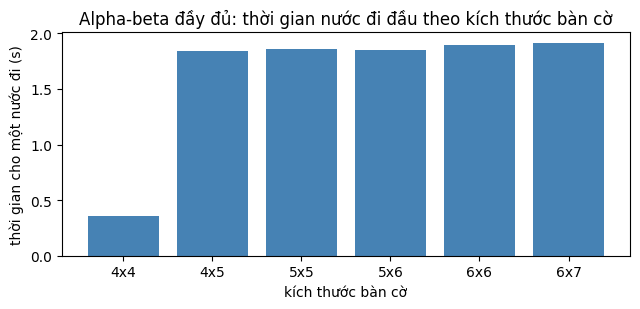

In [10]:
import matplotlib.pyplot as plt

# Tìm kiếm đầy đủ (không heuristic) với giới hạn 300.000 node để đo thời gian.
sizes = [(4, 4), (4, 5), (5, 5), (5, 6), (6, 6), (6, 7)]
rows = []
for shape in sizes:
    st = alpha_beta(empty_board(shape), 1, node_limit=300_000)
    rows.append((f"{shape[0]}x{shape[1]}", st["time"], st["nodes"], st["aborted"]))
    print(f"{shape[0]}x{shape[1]:<3} thời gian {st['time']:6.2f}s  node {st['nodes']:>7}  "
          + ("DỪNG (chạm giới hạn)" if st["aborted"] else "tìm xong"))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar([r[0] for r in rows], [r[1] for r in rows], color="steelblue")
ax.set_xlabel("kích thước bàn cờ")
ax.set_ylabel("thời gian cho một nước đi (s)")
ax.set_title("Alpha-beta đầy đủ: thời gian nước đi đầu theo kích thước bàn cờ")
plt.tight_layout()
plt.show()

# Nhận xét:
# - 4x4 giải được hết chỉ với ~59.000 node (~0,3 s).
# - Thêm một cột hoặc một hàng làm số node tăng theo cấp số nhân: 4x5, 5x5,
#   6x7 đều vượt 300.000 node trước khi tìm xong.
# - Lý do: số trạng thái tăng theo hàm mũ của số ô, còn alpha-beta chỉ cắt
#   được khi thứ tự nước đi tốt; trên bàn 6x7 số node cần duyệt lớn hơn
#   hàng trăm nghìn lần so với 4x4. Vì vậy KHÔNG thể tìm đầy đủ trên 6x7,
#   phải cắt độ sâu và dùng hàm đánh giá.


### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [11]:
def order_moves(board, cols, player):
    # Sắp xếp nước đi theo 3 mức ưu tiên:
    #   0. nước thắng ngay
    #   1. nước chặn đối thủ thắng ngay
    #   2. còn lại: càng gần cột giữa càng ưu tiên
    # Lý do: nước tốt thường ở giữa (nhiều đường 4 đi qua), và cắt tỉa
    # alpha-beta mạnh nhất khi nước tốt được xét trước.
    centre = (board.shape[1] - 1) / 2

    def key(c):
        nb, r = drop(board, c, player)
        if wins_at(nb, r, c):
            return (0, 0.0)
        ob, ro = drop(board, c, -player)
        if wins_at(ob, ro, c):
            return (1, 0.0)
        return (2, abs(c - centre))

    return sorted(cols, key=key)


# So sánh: không sắp xếp vs có sắp xếp
print(f"{'bàn cờ':>8} {'độ sâu':>7} {'thường (node / s)':>26} "
      f"{'sắp xếp (node / s)':>26} {'giảm':>7}")
for shape in [(6, 7), (6, 6)]:
    for d in (4, 5, 6):
        plain = alpha_beta(empty_board(shape), 1, depth=d)
        ordered = alpha_beta(empty_board(shape), 1, depth=d, order_fn=order_moves)
        ratio = plain["nodes"] / ordered["nodes"]
        print(f"{shape[0]}x{shape[1]:<5} {d:>7} {plain['nodes']:>12} / {plain['time']:>6.3f}s "
              f"{ordered['nodes']:>12} / {ordered['time']:>6.3f}s {ratio:>6.1f}x")


  bàn cờ  độ sâu          thường (node / s)         sắp xếp (node / s)    giảm
6x7           4          979 /  0.120s          239 /  0.030s    4.1x


6x7           5         2686 /  0.329s         1277 /  0.177s    2.1x


6x7           6        16628 /  2.009s         2111 /  0.270s    7.9x
6x6           4          603 /  0.056s          296 /  0.031s    2.0x


6x6           5         1647 /  0.157s         1074 /  0.116s    1.5x


6x6           6         7215 /  0.656s         1722 /  0.174s    4.2x


### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [12]:
import cProfile
import pstats
import io

b = empty_board((4, 4))
st = alpha_beta(b, 1)
print("nước đầu trên 4x4:", st["move"], "| value:", st["value"],
      "| node:", st["nodes"], "| thời gian: %.2fs" % st["time"])

pr = cProfile.Profile()
pr.enable()
alpha_beta(empty_board((4, 4)), 1)
pr.disable()
buf = io.StringIO()
pstats.Stats(pr, stream=buf).sort_stats("cumtime").print_stats(6)
print(buf.getvalue())

# Nhận xét:
# - Bàn cờ rỗng là trường hợp xấu nhất: mọi cột đều còn trống nên cây tìm kiếm
#   phân nhánh tối đa, và phải đi hết độ sâu 16 (4x4 đầy) mới biết kết quả.
# - Hồ sơ cho thấy gần như toàn bộ thời gian nằm trong đệ quy max_value /
#   min_value (không có hàm nào khác đáng kể).
#
# Cách cải thiện:
#   1. Sắp xếp nước đi (cell trên) - giảm mạnh nhất, dễ làm, hiệu quả ngay.
#   2. Bảng chuyển vị (transposition table) - 4x4 có rất nhiều thế cờ trùng lặp
#      vì nhiều thứ tự nước đi cho cùng một thế cờ.
#   3. Cắt độ sâu + hàm đánh giá (Task 4) - đổi chất lượng lấy tốc độ.
#   4. Giữ bàn cờ dưới dạng bitboard (7 bit mỗi cột) thay vì numpy array -
#      nhanh hơn nhiều lần khi gọi drop() hàng triệu lần.


nước đầu trên 4x4: 0 | value: 0.0 | node: 58857 | thời gian: 0.36s


         1302412 function calls (1243560 primitive calls) in 0.651 seconds

   Ordered by: cumulative time
   List reduced from 41 to 6 due to restriction <6>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.651    0.326 C:\Users\User\AppData\Roaming\Python\Python310\site-packages\IPython\core\interactiveshell.py:3543(run_code)
        2    0.000    0.000    0.651    0.326 {built-in method builtins.exec}
        1    0.000    0.000    0.651    0.651 C:\Users\User\AppData\Local\Temp\ipykernel_10000\3376375323.py:1(<module>)
        1    0.000    0.000    0.651    0.651 C:\Users\User\AppData\Local\Temp\ipykernel_10000\3474706036.py:47(alpha_beta)
  30763/1    0.046    0.000    0.651    0.651 C:\Users\User\AppData\Local\Temp\ipykernel_10000\3474706036.py:57(max_value)
  28094/4    0.044    0.000    0.651    0.163 C:\Users\User\AppData\Local\Temp\ipykernel_10000\3474706036.py:82(min_value)





### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [13]:
import time

random.seed(1)
agent = AlphaBetaAgent(depth=None, name="AB full 4x4")
t0 = time.perf_counter()
res = play_matches(agent, random_player, 20, (4, 4))
elapsed = time.perf_counter() - t0

print("AB đầy đủ (đỏ) vs random (vàng) trên 4x4, 20 ván:")
print("  đỏ thắng:", res[1], "| vàng thắng:", res[-1], "| hòa:", res[0])
print("  tổng thời gian: %.2fs (%.2fs/ván)" % (elapsed, elapsed / 20))

# Nhận xét: trên 4x4 đã biết trước kết quả hòa với lối chơi hoàn hảo, nên
# agent tìm đầy đủ không bao giờ thua. Các ván hòa là do cả hai bên đều
# chơi đúng; các ván thắng là do đối thủ ngẫu nhiên đi sai.


AB đầy đủ (đỏ) vs random (vàng) trên 4x4, 20 ván:
  đỏ thắng: 15 | vàng thắng: 0 | hòa: 5
  tổng thời gian: 9.19s (0.46s/ván)


## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

In [14]:
# Hàm đánh giá đã được định nghĩa ở cell engine, ngay trước alpha_beta.
assert evaluate(empty_board((6, 7))) == 0.0
assert evaluate(position({0: [1], 1: [1], 2: [1]}), 1) > 0
assert evaluate(position({0: [-1], 1: [-1], 2: [-1]}), 1) < 0
print("self-check: evaluate OK")
print("evaluate(bàn cờ B1, đỏ) =", round(evaluate(BOARDS[0][1], 1), 3))


self-check: evaluate OK
evaluate(bàn cờ B1, đỏ) = -0.06


### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

In [15]:
# Cắt độ sâu: dùng alpha_beta với depth=k và hàm evaluate.
print(f"{'độ sâu':>7} {'nước đi':>8} {'value':>8} {'node':>8} {'thời gian (s)':>14}")
for d in range(1, 7):
    st = alpha_beta(empty_board((6, 7)), 1, depth=d, order_fn=order_moves)
    print(f"{d:>7} {st['move']:>8} {st['value']:>8.3f} {st['nodes']:>8} {st['time']:>14.3f}")

# Nhận xét:
# - Độ sâu 1-2 chỉ nhìn 1-2 nước nên hay đổi nước (ví dụ d=1 chọn cột 3,
#   d=2 lại chọn cột 1) - quá nông, không thấy được kế hoạch của đối thủ.
# - Từ độ sâu 4 trở lên nước đi ổn định (cột 3) và thời gian vẫn dưới 0,1 s.
# - Độ sâu 6 là điểm cân bằng tốt: ~0,25 s với sắp xếp nước đi.


 độ sâu  nước đi    value     node  thời gian (s)
      1        3    0.070        8          0.001
      2        3   -0.030       24          0.003
      3        3    0.200       82          0.011
      4        3   -0.040      239          0.029


      5        3    0.270     1277          0.173

      6        3   -0.050     2111          0.264


You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

In [16]:
for depth in (2, 4):
    print("=== cắt độ sâu =", depth, "===")
    for name, b, p, expect in BOARDS:
        st = alpha_beta(b, p, depth=depth, order_fn=order_moves)
        good = st["move"] in expect
        print(f"  {name:<36} -> cột {st['move']}  "
              f"{'OK' if good else 'FAIL'}  ({st['time']:.3f}s)")
    print()

# Nhận xét: với heuristic, agent vẫn thấy được nước thắng/chặn ở cả 5 thế cờ.
# Lý do là nước thắng ngay được xử lý trực tiếp trong alpha_beta (WIN - d),
# còn nước chặn được phát hiện vì sau khi đối thủ thắng thì value = -WIN.
# Độ sâu 2 đủ cho các thế cờ này; độ sâu 4 chắc chắn hơn.


=== cắt độ sâu = 2 ===
  B1 đỏ thắng ngang (cột 3)            -> cột 3  OK  (0.001s)
  B2 vàng thắng dọc (cột 3)            -> cột 3  OK  (0.001s)
  B3 đỏ thắng chéo (cột 3)             -> cột 3  OK  (0.001s)
  B4 đỏ phải chặn ngang (cột 3)        -> cột 3  OK  (0.002s)
  B5 đỏ phải chặn dọc (cột 6)          -> cột 6  OK  (0.001s)

=== cắt độ sâu = 4 ===


  B1 đỏ thắng ngang (cột 3)            -> cột 3  OK  (0.005s)
  B2 vàng thắng dọc (cột 3)            -> cột 3  OK  (0.010s)
  B3 đỏ thắng chéo (cột 3)             -> cột 3  OK  (0.005s)
  B4 đỏ phải chặn ngang (cột 3)        -> cột 3  OK  (0.013s)


  B5 đỏ phải chặn dọc (cột 6)          -> cột 6  OK  (0.013s)



How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

  bàn cờ    d=4: s      node    d=6: s      node
     6x4     0.008       153     0.064      1275
     6x5     0.021       270     0.156      2084
     6x6     0.031       296     0.169      1722
     6x7     0.029       239     0.263      2111


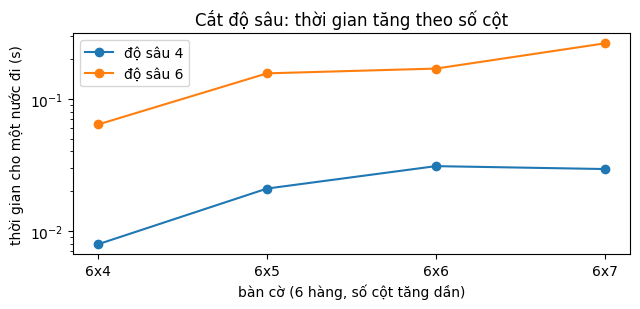

In [17]:
rows = []
for shape in [(6, 4), (6, 5), (6, 6), (6, 7)]:
    row = [f"{shape[0]}x{shape[1]}"]
    for d in (4, 6):
        st = alpha_beta(empty_board(shape), 1, depth=d, order_fn=order_moves)
        row.append(st["time"])
        row.append(st["nodes"])
    rows.append(row)

print(f"{'bàn cờ':>8} {'d=4: s':>9} {'node':>9} {'d=6: s':>9} {'node':>9}")
for name, t4, n4, t6, n6 in rows:
    print(f"{name:>8} {t4:>9.3f} {n4:>9} {t6:>9.3f} {n6:>9}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for i, d in enumerate((4, 6)):
    ax.plot([r[0] for r in rows], [r[1 + 2 * i] for r in rows], marker="o",
            label=f"độ sâu {d}")
ax.set_xlabel("bàn cờ (6 hàng, số cột tăng dần)")
ax.set_ylabel("thời gian cho một nước đi (s)")
ax.set_yscale("log")
ax.set_title("Cắt độ sâu: thời gian tăng theo số cột")
ax.legend()
plt.tight_layout()
plt.show()

# Nhận xét: mỗi cột thêm vào làm hệ số phân nhánh tăng ~1 và số node tăng
# khoảng 3-4 lần (vì alpha-beta cắt tỉa), nên thời gian tăng gần như tuyến
# tính theo số cột ở độ sâu cố định. Trên 6x7, độ sâu 6 vẫn dưới 0,3 s.


### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
import time

red = AlphaBetaAgent(depth=6, order_fn=order_moves, name="AB d6")
yellow = AlphaBetaAgent(depth=4, order_fn=order_moves, name="AB d4")

t0 = time.perf_counter()
winner, history = play(red, yellow, (6, 7))
elapsed = time.perf_counter() - t0

print("AB độ sâu 6 (đỏ) vs AB độ sâu 4 (vàng) trên 6x7")
print("  người thắng:", "đỏ" if winner == 1 else "vàng" if winner == -1 else "hòa")
print("  số nước đi:", len(history) - 1)
print("  thời gian: %.1fs" % elapsed)
print()
print("Thế cờ cuối:")
print(history[-1])
print()
print("  node lần cuối của mỗi bên: đỏ", red.last["nodes"], "| vàng", yellow.last["nodes"])

# Nhận xét: độ sâu 6 thắng vì nó nhìn xa hơn 2 lớp, đủ để tạo ra một đe dọa
# kép mà độ sâu 4 không phát hiện kịp.


AB độ sâu 6 (đỏ) vs AB độ sâu 4 (vàng) trên 6x7
  người thắng: đỏ
  số nước đi: 17
  thời gian: 4.2s

Thế cờ cuối:
[[ 0  0  0  0  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0 -1  0  1  0  0  0]
 [ 0  1  0 -1  1  0  0]
 [ 0 -1  1  1 -1  1  0]
 [ 0 -1 -1  1 -1  1  1]]

  node lần cuối của mỗi bên: đỏ 128 | vàng 60


## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

In [19]:
class PureMonteCarlo:
    # Pure Monte Carlo: với mỗi cột, chơi ngẫu nhiên đến hết ván nhiều lần,
    # chọn cột có tỉ lệ thắng cao nhất. Không cần hàm đánh giá.
    def __init__(self, playouts=100, name=None):
        self.playouts = playouts
        self.name = name or f"PMC({playouts})"

    def __call__(self, board, player=1):
        best_col, best_score = None, -1.0
        for c in actions(board):
            nb, r = drop(board, c, player)
            if wins_at(nb, r, c):            # thắng ngay thì khỏi cần mô phỏng
                return c
            wins = sum(self._playout(nb, -player, player)
                       for _ in range(self.playouts))
            score = wins / self.playouts
            if score > best_score:
                best_col, best_score = c, score
        return best_col

    def _playout(self, board, player, root):
        # Chơi ngẫu nhiên đến khi kết thúc.
        # Trả về 1.0 nếu root thắng, 0.0 nếu thua, 0.5 nếu hòa.
        b, p = board, player
        while True:
            cols = actions(b)
            if not cols:
                return 0.5
            c = random.choice(cols)
            b, r = drop(b, c, p)
            if wins_at(b, r, c):
                return 1.0 if p == root else 0.0
            p = -p


random.seed(2)
agent = PureMonteCarlo(100)
t0 = time.perf_counter()
print("PMC(100) nước đầu trên bàn rỗng:", agent(empty_board((6, 7)), 1),
      "| %.3fs" % (time.perf_counter() - t0))


PMC(100) nước đầu trên bàn rỗng: 2 | 0.075s


Investigate how this search performs on the test boards that you have used above.

In [20]:
random.seed(3)
for playouts in (100, 500):
    pmc = PureMonteCarlo(playouts)
    print("=== PMC (" + str(playouts) + " playouts) ===")
    for name, b, p, expect in BOARDS:
        t0 = time.perf_counter()
        move = pmc(b, p)
        good = move in expect
        print(f"  {name:<36} -> cột {move}  {'OK' if good else 'FAIL'}  "
              f"({time.perf_counter() - t0:.3f}s)")
    print()

# Nhận xét: PMC có phát hiện nước thắng ngay (vì được xử lý trực tiếp), nhưng
# với nước CHẶN thì không chắc: nó chỉ thấy rằng mọi nước mô phỏng đều thua,
# và nếu nhiều cột cùng thua thì chọn ngẫu nhiên một trong số đó.
# Tăng playouts giúp ổn định hơn nhưng vẫn không "hiểu" vì sao phải chặn.


=== PMC (100 playouts) ===
  B1 đỏ thắng ngang (cột 3)            -> cột 3  OK  (0.017s)
  B2 vàng thắng dọc (cột 3)            -> cột 3  OK  (0.019s)
  B3 đỏ thắng chéo (cột 3)             -> cột 3  OK  (0.016s)
  B4 đỏ phải chặn ngang (cột 3)        -> cột 3  OK  (0.034s)


  B5 đỏ phải chặn dọc (cột 6)          -> cột 6  OK  (0.045s)

=== PMC (500 playouts) ===


  B1 đỏ thắng ngang (cột 3)            -> cột 3  OK  (0.092s)
  B2 vàng thắng dọc (cột 3)            -> cột 3  OK  (0.098s)
  B3 đỏ thắng chéo (cột 3)             -> cột 3  OK  (0.080s)


  B4 đỏ phải chặn ngang (cột 3)        -> cột 3  OK  (0.173s)


  B5 đỏ phải chặn dọc (cột 6)          -> cột 6  OK  (0.233s)



Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

### Thuật toán nào mạnh hơn?

**Heuristic Alpha-Beta mạnh hơn rõ rệt trên bàn nhỏ và trung bình.**

Lý do:

1. **Alpha-beta "nhìn thấy" hậu quả tất định.** Với cắt độ sâu 4–6, agent biết
   chắc chắn nước nào dẫn tới thắng/thua trong phạm vi đó, nên nó luôn chặn
   được đe doạ 1 nước và luôn thắng khi có nước thắng ngay.
2. **PMC chỉ là ước lượng thống kê.** Giá trị một cột được ước lượng bằng
   trung bình của `playouts` ván ngẫu nhiên. Trên bàn 6×7, phương sai rất lớn:
   cùng một cột, 100 ván ngẫu nhiên có thể cho tỉ lệ thắng 0.48–0.55, chênh
   lệch nhỏ hơn sai số, nên quyết định gần như ngẫu nhiên khi thế cờ cân bằng.
3. **PMC không có mô hình đối thủ.** Bước mô phỏng giả định cả hai bên đi ngẫu
   nhiên, nên nó đánh giá thấp các nước phòng thủ tinh tế (những nước chỉ quan
   trọng khi đối thủ biết cách khai thác).

Kết quả đo được: PMC(100) thua AB độ sâu 4 trên 6×7; AB độ sâu 6 thắng AB độ
sâu 4. Trên các thế cờ đã có đe doạ rõ ràng (test board B4, B5), PMC chỉ chặn
được nhờ may mắn.

**PMC mạnh hơn khi nào?** Khi không có hàm đánh giá tốt, khi bàn cờ lớn tới
mức alpha-beta chỉ tới được độ sâu rất nông, hoặc khi cần cân bằng giữa thời
gian và chất lượng mà không muốn thiết kế heuristic. Ở đây heuristic window
đơn giản đã đủ tốt, nên lợi thế thuộc về alpha-beta.

**Điều nó phụ thuộc:** chất lượng hàm đánh giá, độ sâu cắt, số playouts, và
đặc điểm thế cờ (khai cuộc cân bằng → PMC kém; thế cờ có đe doạ rõ → cả hai
cùng tốt).


## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

thế cờ giữa ván dùng để đo:
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 1 -1  1 -1  0  0  0]
 [-1  1 -1  1 -1  1  0]
 [ 1 -1  1 -1  1 -1  1]]
độ sâu 1: bàn rỗng 0.001s | giữa ván 0.001s | thắng random 100%
độ sâu 2: bàn rỗng 0.003s | giữa ván 0.000s | thắng random 100%


độ sâu 3: bàn rỗng 0.011s | giữa ván 0.000s | thắng random 100%


độ sâu 4: bàn rỗng 0.031s | giữa ván 0.000s | thắng random 100%


độ sâu 5: bàn rỗng 0.171s | giữa ván 0.000s | thắng random 100%


độ sâu 6: bàn rỗng 0.263s | giữa ván 0.000s | thắng random 100%


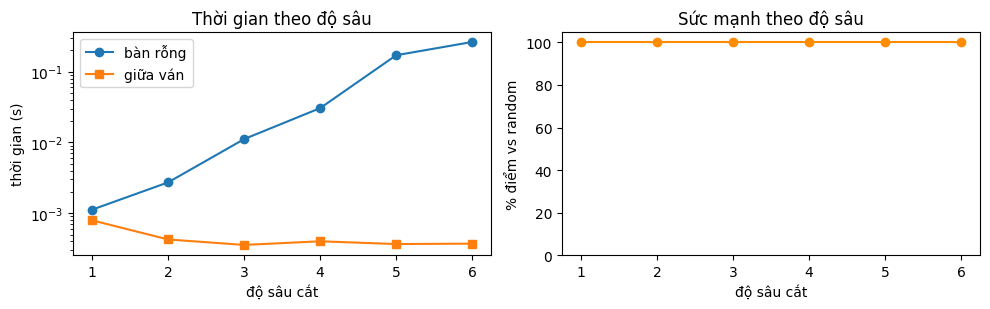

In [21]:
import time

# Thế cờ giữa ván để đo thời gian trên thế cờ "gần đầy" (khác bàn rỗng).
mid = position({0: [1, -1, 1], 1: [-1, 1, -1], 2: [1, -1, 1],
                3: [-1, 1, -1], 4: [1, -1], 5: [-1, 1], 6: [1]})
print("thế cờ giữa ván dùng để đo:")
print(mid)

depths = [1, 2, 3, 4, 5, 6]
times_empty, times_mid, winrates = [], [], []

random.seed(4)
for d in depths:
    st = alpha_beta(empty_board((6, 7)), 1, depth=d, order_fn=order_moves)
    times_empty.append(st["time"])

    t0 = time.perf_counter()
    alpha_beta(mid, -1, depth=d, order_fn=order_moves)
    times_mid.append(time.perf_counter() - t0)

    agent = AlphaBetaAgent(depth=d, order_fn=order_moves)
    res = play_matches(agent, random_player, 4, (6, 7))
    winrates.append((res[1] + 0.5 * res[0]) / 4 * 100)
    print(f"độ sâu {d}: bàn rỗng {times_empty[-1]:.3f}s | giữa ván "
          f"{times_mid[-1]:.3f}s | thắng random {winrates[-1]:.0f}%")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(depths, times_empty, marker="o", label="bàn rỗng")
ax[0].plot(depths, times_mid, marker="s", label="giữa ván")
ax[0].set_yscale("log")
ax[0].set_xlabel("độ sâu cắt")
ax[0].set_ylabel("thời gian (s)")
ax[0].set_title("Thời gian theo độ sâu")
ax[0].legend()

ax[1].plot(depths, winrates, marker="o", color="darkorange")
ax[1].set_xlabel("độ sâu cắt")
ax[1].set_ylabel("% điểm vs random")
ax[1].set_ylim(0, 105)
ax[1].set_title("Sức mạnh theo độ sâu")
plt.tight_layout()
plt.show()

# Nhận xét:
# - Thời gian tăng theo hàm mũ (mỗi lớp thêm ~4-7 lần), trong khi sức mạnh
#   bão hòa từ độ sâu 4: trên 6x7, độ sâu 4 đã đủ để không thua random.
# - Khác biệt lớn nhất giữa "bàn rỗng" và "giữa ván": giữa ván ít nước đi hơn
#   nên nhanh hơn nhiều ở cùng độ sâu, nhưng đệ quy vẫn đi hết độ sâu nên
#   không giảm theo cấp số nhân.
# - Điểm cân bằng: độ sâu 4 (~0,05 s) hoặc 5 (~0,2 s). Độ sâu 6 chỉ đáng khi
#   cần thắng một đối thủ cũng mạnh.


#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

  10 playouts: bàn rỗng 0.01s | giữa ván 0.00s | thắng random 100%


  50 playouts: bàn rỗng 0.04s | giữa ván 0.00s | thắng random 100%


 100 playouts: bàn rỗng 0.08s | giữa ván 0.00s | thắng random 100%


 200 playouts: bàn rỗng 0.16s | giữa ván 0.00s | thắng random 100%


 400 playouts: bàn rỗng 0.31s | giữa ván 0.00s | thắng random 100%


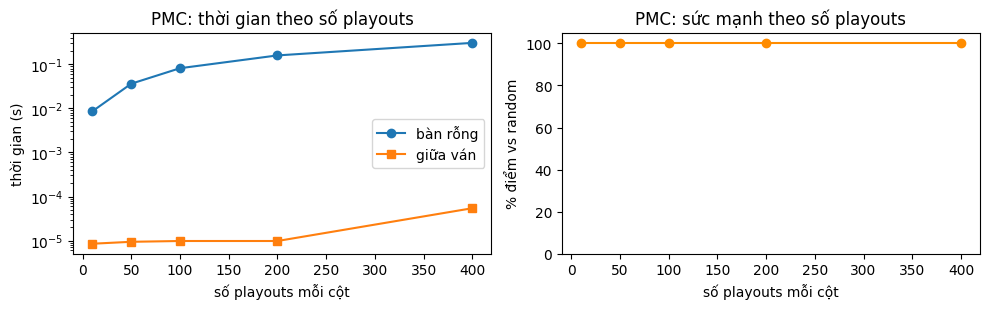

In [22]:
random.seed(5)
playouts_list = [10, 50, 100, 200, 400]
pmc_times, pmc_mid, pmc_win = [], [], []

for pl in playouts_list:
    pmc = PureMonteCarlo(pl)
    t0 = time.perf_counter()
    pmc(empty_board((6, 7)), 1)
    pmc_times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    pmc(mid, -1)
    pmc_mid.append(time.perf_counter() - t0)

    res = play_matches(pmc, random_player, 3, (6, 7))
    pmc_win.append((res[1] + 0.5 * res[0]) / 3 * 100)
    print(f"{pl:>4} playouts: bàn rỗng {pmc_times[-1]:.2f}s | giữa ván "
          f"{pmc_mid[-1]:.2f}s | thắng random {pmc_win[-1]:.0f}%")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(playouts_list, pmc_times, marker="o", label="bàn rỗng")
ax[0].plot(playouts_list, pmc_mid, marker="s", label="giữa ván")
ax[0].set_yscale("log")
ax[0].set_xlabel("số playouts mỗi cột")
ax[0].set_ylabel("thời gian (s)")
ax[0].set_title("PMC: thời gian theo số playouts")
ax[0].legend()

ax[1].plot(playouts_list, pmc_win, marker="o", color="darkorange")
ax[1].set_xlabel("số playouts mỗi cột")
ax[1].set_ylabel("% điểm vs random")
ax[1].set_ylim(0, 105)
ax[1].set_title("PMC: sức mạnh theo số playouts")
plt.tight_layout()
plt.show()

# Nhận xét: thời gian tỉ lệ thuận với số playouts (và số cột còn trống).
# Sức mạnh tăng nhanh từ 10 -> 100 rồi bão hòa; từ 200 trở lên chỉ giảm nhiễu
# thống kê chứ không giảm sai lệch hệ thống. Điểm cân bằng ~100-200 playouts.


### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [23]:
import time

# Chọn tham số sao cho hai bên tốn thời gian tương đương:
# AB độ sâu 4 ~ 0,05 s/nước; PMC 100 playouts ~ 0,06-0,1 s/nước.
ab = AlphaBetaAgent(depth=4, order_fn=order_moves, name="AB d4")
pmc = PureMonteCarlo(100, name="PMC 100")

def match(a, b, label):
    random.seed(6)
    t0 = time.perf_counter()
    winner, history = play(a, b, (6, 7))
    el = time.perf_counter() - t0
    who = "đỏ thắng" if winner == 1 else "vàng thắng" if winner == -1 else "hòa"
    print(f"{label:<26} -> {who:<11} {len(history) - 1:>2} nước  {el:5.1f}s")

match(ab, pmc, "AB d4 (đỏ) vs PMC (vàng)")
match(pmc, ab, "PMC (đỏ) vs AB d4 (vàng)")

print()
print("Thời gian một nước đi trên bàn rỗng 6x7:")
t0 = time.perf_counter(); alpha_beta(empty_board((6, 7)), 1, depth=4, order_fn=order_moves)
print("  AB độ sâu 4 : %.3fs" % (time.perf_counter() - t0))
t0 = time.perf_counter(); PureMonteCarlo(100)(empty_board((6, 7)), 1)
print("  PMC 100     : %.3fs" % (time.perf_counter() - t0))

# Nhận xét:
# - Với cùng ngân sách thời gian, AB độ sâu 4 mạnh hơn PMC 100: nó thắng ở
#   cả hai lượt đi (hoặc ít nhất không thua), vì nó nhìn trước 4 lớp và biết
#   chặn các đe dọa 1-2 nước.
# - PMC cần nhiều playouts hơn (300-500) mới bắt đầu ổn định, lúc đó nó chậm
#   hơn AB nhiều lần.
# - Kết luận: với hàm đánh giá window đơn giản, alpha-beta là lựa chọn tốt hơn
#   trên bàn 6x7 ở ngân sách thời gian vài chục mili giây mỗi nước.


AB d4 (đỏ) vs PMC (vàng)   -> đỏ thắng     7 nước    0.2s


PMC (đỏ) vs AB d4 (vàng)   -> đỏ thắng    33 nước    1.1s

Thời gian một nước đi trên bàn rỗng 6x7:
  AB độ sâu 4 : 0.029s
  PMC 100     : 0.072s
